In [1]:
%matplotlib inline

import csv
import hashlib
import inspect
import json
import sys
import copy
from dataclasses import fields
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import spence
from IPython.display import display

root = Path.cwd().resolve()
while not (root / "gaas_mc").is_dir() and root != root.parent:
    root = root.parent
if not (root / "gaas_mc").is_dir():
    raise FileNotFoundError("Open this notebook from the GaAsTransport repository or examples folder.")
sys.path.insert(0, str(root))

try:
    from beamphysics import ParticleGroup
except ImportError:
    from pmd_beamphysics import ParticleGroup

from gaas_mc.emission import simulate_emission
from gaas_mc.constants import C_LIGHT, M0, PS, Q_E, per_cm3, EV
from gaas_mc.material import Sample, gaas_chubenko2021

out = root / "examples" / "out" / "particlegroup_tutorial"
out.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
print("Repository:", root)
print("Outputs:", out)

Repository: C:\Users\acb20\OneDrive\Desktop\Claude\GaAsTransport
Outputs: C:\Users\acb20\OneDrive\Desktop\Claude\GaAsTransport\examples\out\particlegroup_tutorial


In [2]:
def metal_K(Ekin, hvMinusPhiminusV, kT):
    return Ekin / ((1 + np.exp((Ekin - hvMinusPhiminusV) / kT))* kT**2* (-spence(1 + np.exp(hvMinusPhiminusV / kT))))

def image_V(z0nm):
    return 0.359991/z0nm

In [151]:
params = dict(
    hv_eV=1.550, # 1.550,                 # Photon energy [eV]; must be allowed by excitation and absorption models.
    p_cm3=1e19,                # Acceptor/hole density [cm^-3].
    chi_eV= 0.0,                 # Local surface affinity [eV]; chi_eff = chi - band-bending depth.
    n=1_000_000,                 # Generated electrons (C21 ensemble size); fewer runs faster but noisier.
    t_max_ps=5.0,                # Stop transport at this time [ps]; C21 benchmark uses 370 ps.
    thickness_nm=50,             # None = semi-infinite; e.g. 200.0 gives a 200 nm GaAs layer.
    R_back=0.0,                  # Back reflection probability [0,1]; used only for a finite layer.
    depletion_scattering="bulk", # "bulk" = C21 baseline; "local" = depleted holes/local screening.
    matching_mass="band_edge",   # Interface mass: "band_edge" (C21 default) or "velocity".
    absorption_model=None,      # None or "casey1975+adachi1989" = blended default;
                                # "casey1975" = near-edge data only; "adachi1989" = C21.
                                # Also accepts a constant absorption length [m], a callable
                                # photon energy [J] -> length [m], or a model object with
                                # absorption_coefficient(energy_J) -> alpha [1/m].
    device="auto",              # "auto", "cuda", "cpu" (compiled), or "reference" (NumPy).
    seed=1,                     # Random seed; reproducible for the same setup and engine.
    sigma_xy=0.0,               # Added Gaussian laser-spot rms per axis [m]; 0 = point excitation.
    total_charge=None,          # Emitted bunch charge [C]; None gives charge +e per macroparticle.
)

s = Sample(gaas_chubenko2021(), per_cm3(params['p_cm3']))
E_bb_eV = s.E_bb / EV  

params['chi_eV'] = params['chi_eV'] + E_bb_eV - image_V(3.0)
chi_eff_eV = params['chi_eV'] - E_bb_eV     # effective affinity relative to the bulk conduction band: -0.024 eV
print(f'chi_eff = {params["chi_eV"]:.4g} - {E_bb_eV:.4g} = {chi_eff_eV:.4g} eV')
print(f'Eg_eff = {s.Eg / EV}')
# Catch documentation drift if the driver later gains or removes a parameter.
assert set(params) == set(inspect.signature(simulate_emission).parameters)

chi_eff = 0.5739 - 0.6939 = -0.12 eV
Eg_eff = 1.3613316601052234


`sigma_xy` adds a Gaussian excitation spot to the **lateral displacement accumulated in GaAs**.
At zero spot size, the resulting x/y spread is transport alone. `total_charge` rescales output
macroparticle weights; it does not alter transport or QE. ParticleGroup stores positive charge
weights for electron macroparticles and identifies the species separately.

The driver uses bulk depletion scattering by default; the lower-level `ModelAssumptions()` default
is local. Choose explicitly when comparing results. The reference engine is useful for small checks,
but the compiled engines are more practical for these ensemble sizes.

In [ ]:
started = perf_counter()
run = simulate_emission(**params)
pg = run.particle_group  # An ordinary ParticleGroup: no wrapper is needed.
em = run.emissions      # Extra records, in the same original particle order.

pz_min = 1010.93912*np.sqrt(image_V(3.0))
pg_final = pg[pg.pz >= pz_min]
pg_final.pz = np.sqrt(pg_final.pz**2 - pz_min**2) # remove energy to get over barrier

print(f"Engine: {run.settings['device']}; elapsed: {perf_counter() - started:.1f} s")
print(f"Generated: {run.n_generated:,}; emitted: {run.n_emitted:,}")
print(f"Absorbed fraction of incident photons: {run.absorbed_fraction:.4f}")
print(f"Emission QE: {100 * run.qe:.3f}%; emitted ESP: {100 * run.esp:.2f}%")
print(f"Barrier transmission: {100 * len(pg_final) / len(pg):.3g}%")
display(pg)

0.6969970000000002


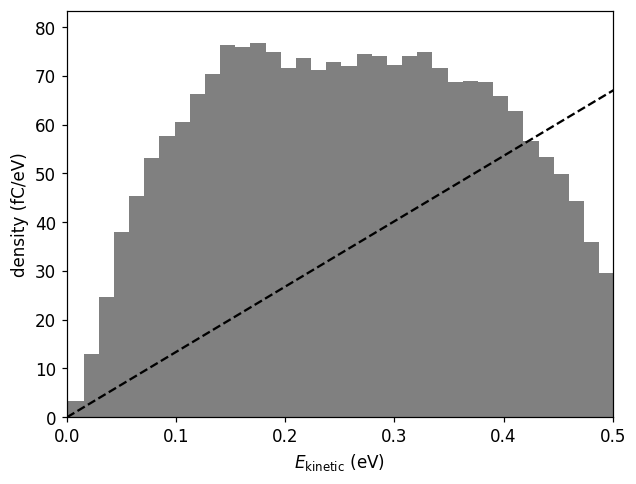

In [148]:
fig = pg.plot('kinetic_energy', bins=70, return_figure=True)
ax = fig.gca()
K = np.linspace(0, np.max(pg.kinetic_energy), 100)
#hvMinusPhiminusV = params['hv_eV'] - s.Eg / EV - chi_eff_eV
hvMinusPhiminusV = params['hv_eV'] - s.material.Eg0 / EV - chi_eff_eV
print(hvMinusPhiminusV)
kT = 0.025
rho = pg.charge * 1e15 * metal_K(K, hvMinusPhiminusV, kT)

ax.plot(K, rho, 'k--')
ax.set_xlim(0, 0.5)
display(fig)
plt.close(fig)

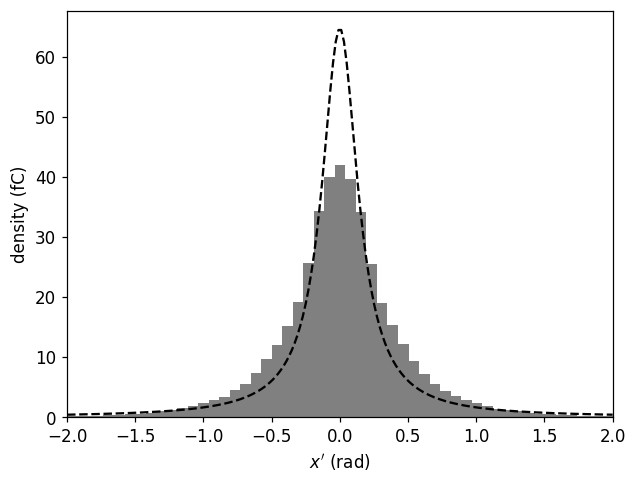

In [149]:
fig = pg.plot('xp', bins=1000, return_figure=True)
ax = fig.gca()

umax1 = 0.067
rm1 = np.sqrt(umax1 / (1-umax1))
#xp1 = np.linspace(-rm1, rm1, 200)
#rho = pg.charge * 1e15 * 2.0/(np.pi * rm1**2) * np.sqrt(rm1**2 - xp1**2) 
#ax.plot(xp1, rho, 'r--')

xp1 = np.linspace(-2, 2, 200)
rm1 = 0.6*rm1
rho = pg.charge * 1e15 * 1.0/(np.pi) * rm1 / (xp1**2 + rm1**2)

ax.plot(xp1, rho, 'k--')

ax.set_xlim(-2, 2)
display(fig)
plt.close(fig)

In [ ]:
em = run.emissions                       # same row order as pg
fig = pg.plot('kinetic_energy', bins=100, return_figure=True)
ax = fig.gca()

edges = np.linspace(-2, 2, 401)
for v, name in enumerate(("Γ", "L", "X")):
    sel = em.valley == v
    if sel.any():
        h, _ = np.histogram(pg.kinetic_energy[sel], bins=edges, weights=pg.weight[sel])
        ax.stairs(1e15 * h / np.diff(edges), edges, color=f"C{v}", lw=1.5, label=f"{name} ({sel.mean():.0%})")

ax.legend()
ax.set_xlim(0, 0.5)
display(fig)
plt.close(fig)

In [ ]:
em = run.emissions                       # same row order as pg
fig = pg.plot('xp', bins=500, return_figure=True)
ax = fig.gca()

edges = np.linspace(-2, 2, 401)
for v, name in enumerate(("Γ", "L", "X")):
    sel = em.valley == v
    if sel.any():
        h, _ = np.histogram(pg.xp[sel], bins=edges, weights=pg.weight[sel])
        ax.stairs(1e15 * h / np.diff(edges), edges, color=f"C{v}", lw=1.5, label=f"{name} ({sel.mean():.0%})")

ax.legend()
ax.set_xlim(-2, 2)
display(fig)
plt.close(fig)

0.5498474476729749,  0.450152552327025


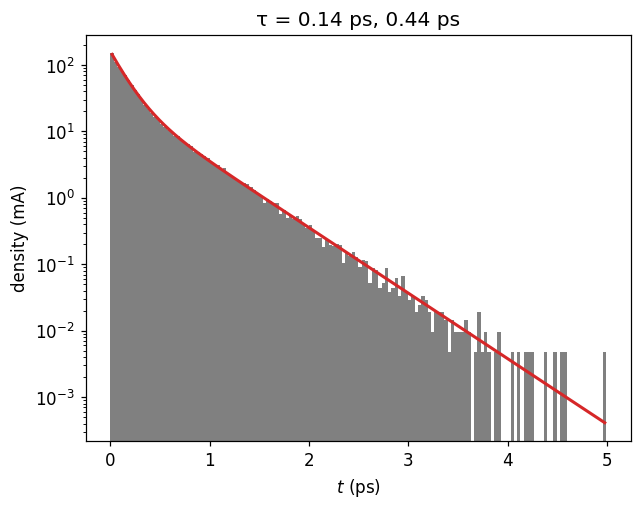

In [150]:
import numpy as np
from scipy.optimize import curve_fit

def fit_hist(fig, model, p0, xmin=None, xmax=None, ax_index=0, **line_kw):
    """Fit model(x, *params) to the bars of a ParticleGroup density plot, in its displayed units."""
    ax = fig.axes[ax_index]
    x = np.array([b.get_x() + b.get_width() / 2 for b in ax.patches])
    y = np.array([b.get_height() for b in ax.patches])
    xmin = x[np.argmax(y)] if xmin is None else xmin          # default: fit the decay after the peak
    m = (x >= xmin) & (x <= (np.inf if xmax is None else xmax)) & (y > 0)
    p0 = p0(x[m], y[m]) if callable(p0) else p0
    popt, pcov = curve_fit(model, x[m], y[m], p0=p0, sigma=np.sqrt(y[m]))   # Poisson weights
    xf = np.linspace(x[m].min(), x[m].max(), 400)
    ax.plot(xf, model(xf, *popt), **{"color": "C3", "lw": 2, **line_kw})
    return popt, np.sqrt(np.diag(pcov))

fig = pg.plot('t', bins=150, return_figure=True)

#exp_decay = lambda t, A, tau: A * np.exp(-t / tau)
#popt, perr = fit_hist(fig, exp_decay, p0=lambda t, y: (y[0], np.ptp(t) / 3))
#fig.axes[0].set_title(f"τ = {popt[1]:.2f} ps")

two_exp = lambda t, A1, tau1, A2, tau2: A1 * np.exp(-t / tau1) + A2 * np.exp(-t / tau2)
popt, perr = fit_hist(fig, two_exp, p0=lambda t, y: (y[0], np.ptp(t) / 30, y[0] / 5, np.ptp(t) / 3))
fig.axes[0].set_title(f"τ = {popt[1]:.2g} ps, {popt[3]:.2g} ps")
A1, tau1, A2, tau2 = popt

print(f'{A1*tau1 / (A1*tau1 + A2*tau2)},  {A2*tau2 / (A1*tau1 + A2*tau2)}')

fig.gca().set_yscale('log')
display(fig)
plt.close(fig)

In [ ]:
from GPT_tools.gpt_plot import gpt_plot_dist1d, gpt_plot_dist2d

In [ ]:
%matplotlib widget
gpt_plot_dist2d(pg, 'pz', 'px', xlim=[0, 700], ylim=[-500, 500], units=['eV/c','eV/c'], axis='equal')

In [ ]:
%matplotlib inline